## CNN - working with real images

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#### Write a function convolve2d that takes an image and a kernel (aka filter). It pads the image around and then slides the kernel to produce the output. 

In [2]:
def convolve2d(image, kernel): #image and kernel are np.arrays
    h, w = image.shape  #image height and width
    kh, kw = kernel.shape #kernel height and width

    pad_h = kh // 2 # padding height is half the kernel height
    pad_w = kw // 2  # paddingwidth is half the kernel width

    padded = np.pad(image,
                    ((pad_h,pad_h),(pad_w,pad_w)),
                    mode='constant')   #add extra values around the boundaries of array

    output = np.zeros_like(image)  #initialize output with 0s.

    for r in range(h):
        for c in range(w):
            region = padded[r:r+kh, c:c+kw]   #select the range from the image to be blurred
            output[r,c] = np.sum(region * kernel)  #multiply with kernel and add 

    return output


#### Prepare the image

In [ ]:
from PIL import Image

# Load your image
img = Image.open("data/goat.jpg")

# Convert to grayscale
img = img.convert("L")

# Convert to NumPy array
camera = np.array(img, dtype=float)

#### Create blur_kernel and create blurred image

In [7]:
blur_kernel = np.ones((5,5))/25
blur_camera = convolve2d(camera, blur_kernel)

#### Create outline_kernel and create outliney image

In [12]:
### holy crud there are complex numbers below us here. These are cool, but ulitimately unimportant for now.
outline_kernel = np.array([[ -3-3j, 0-10j,  +3 -3j],
                   [-10+0j, 0+ 0j, +10 +0j],
                   [ -3+3j, 0+10j,  +3 +3j]])


outline_camera = convolve2d(camera, outline_kernel)

C:\Users\n_dwi\AppData\Local\Temp\ipykernel_40576\1125169604.py:17: ComplexWarning: Casting complex values to real discards the imaginary part
  output[r,c] = np.sum(region * kernel)  #multiply with kernel and add


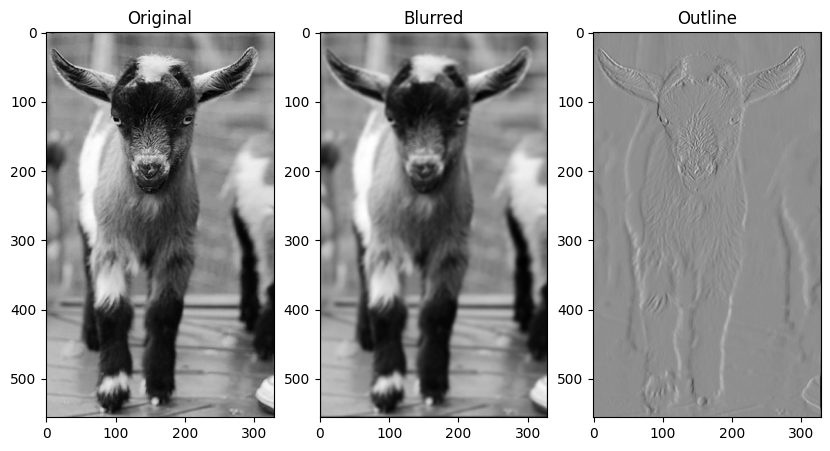

In [11]:
fig, ax = plt.subplots(1,3, figsize=(10,5))

ax[0].imshow(camera, cmap="gray")
ax[0].set_title("Original")

ax[1].imshow(blur_camera, cmap="gray")
ax[1].set_title("Blurred")

ax[2].imshow(outline_camera, cmap="gray")
ax[2].set_title("Outline")

plt.show()